# 01 · Exploración del dataset de placas

Autores: Daniel Guevara y Christian Guerra. El modo predeterminado reproduce el análisis de las evidencias agregadas publicadas. No requiere descargar fotografías privadas ni estima atributos demográficos.

In [1]:
from pathlib import Path
import sys, json, csv, hashlib
from html import escape
from IPython.display import display, Markdown, HTML, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/paths.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
def load(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def table(rows):
    if not rows:
        return display(Markdown("Sin filas."))
    keys = list(rows[0])
    head = "".join("<th>" + escape(str(k)) + "</th>" for k in keys)
    body = "".join("<tr>" + "".join("<td>" + escape(str(r.get(k, ""))) + "</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML("<table><thead><tr>"+head+"</tr></thead><tbody>"+body+"</tbody></table>"))
print("Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.")


Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.


## Fuente y particiones

Capturas del sistema laboral del autor, con autorización de uso académico y publicación declarada por el equipo. No se ha indicado una licencia abierta del dataset. Una clase: placa. La auditoría comprueba formato y duplicados exactos, no independencia por vehículo ni corrección visual de todas las cajas.

In [2]:
eda = load("results/metrics/analisis_datos.json")
table([{"partición": k, **v} for k,v in eda["splits"].items()])
assert sum(v["images"] for v in eda["splits"].values()) == eda["total_images"]
print("Total:",eda["total_images"],"imágenes y",eda["total_valid_boxes"],"cajas")

partición,images,empty_labels,valid_boxes,readable_images,multi_plate_images,orphan_labels
train,5865,0,6570,5865,678,0
val,733,0,819,733,84,0
test,734,0,819,734,80,0


Total: 7332 imágenes y 8208 cajas


## Seis visualizaciones EDA

Son figuras generadas por `src.analizar_datos` desde las imágenes y etiquetas originales. Sus resultados se conservan para revisión desde una copia pública.

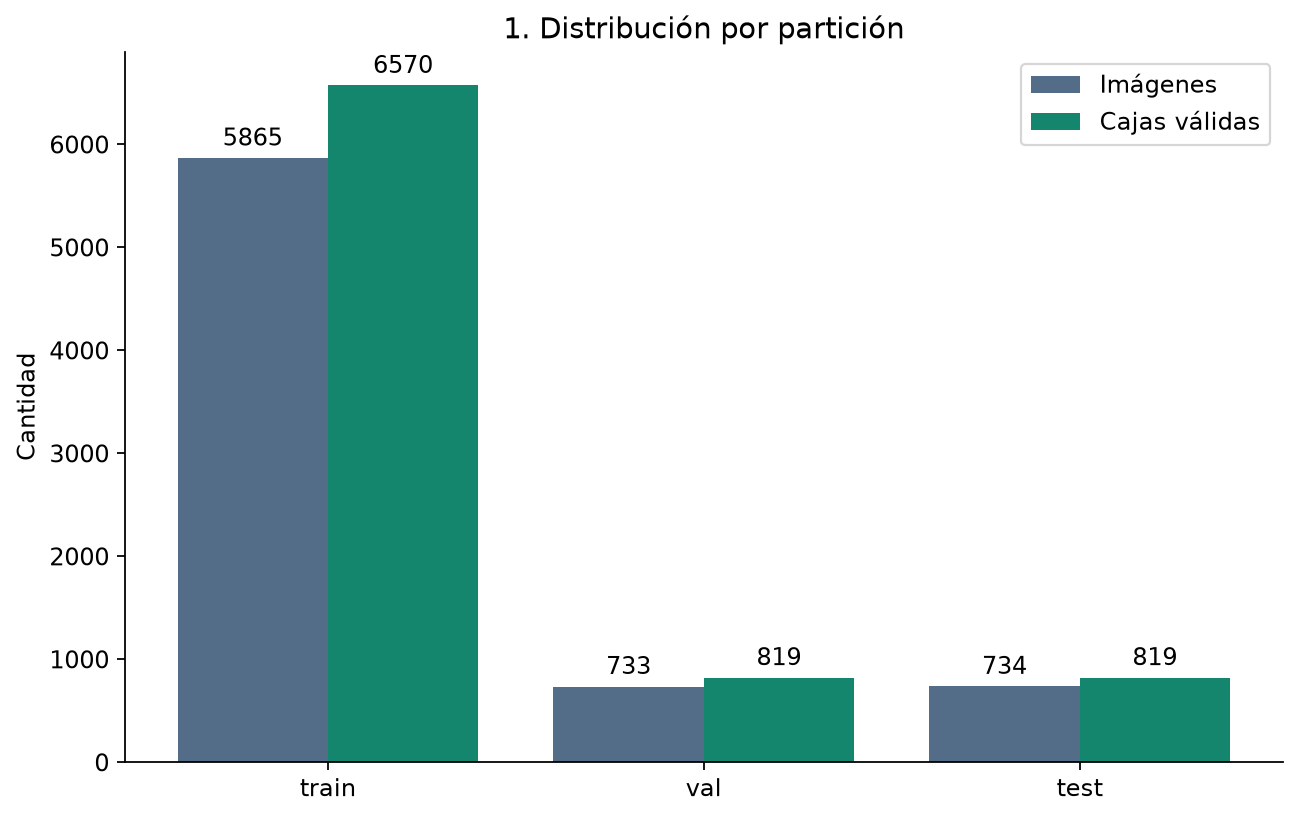

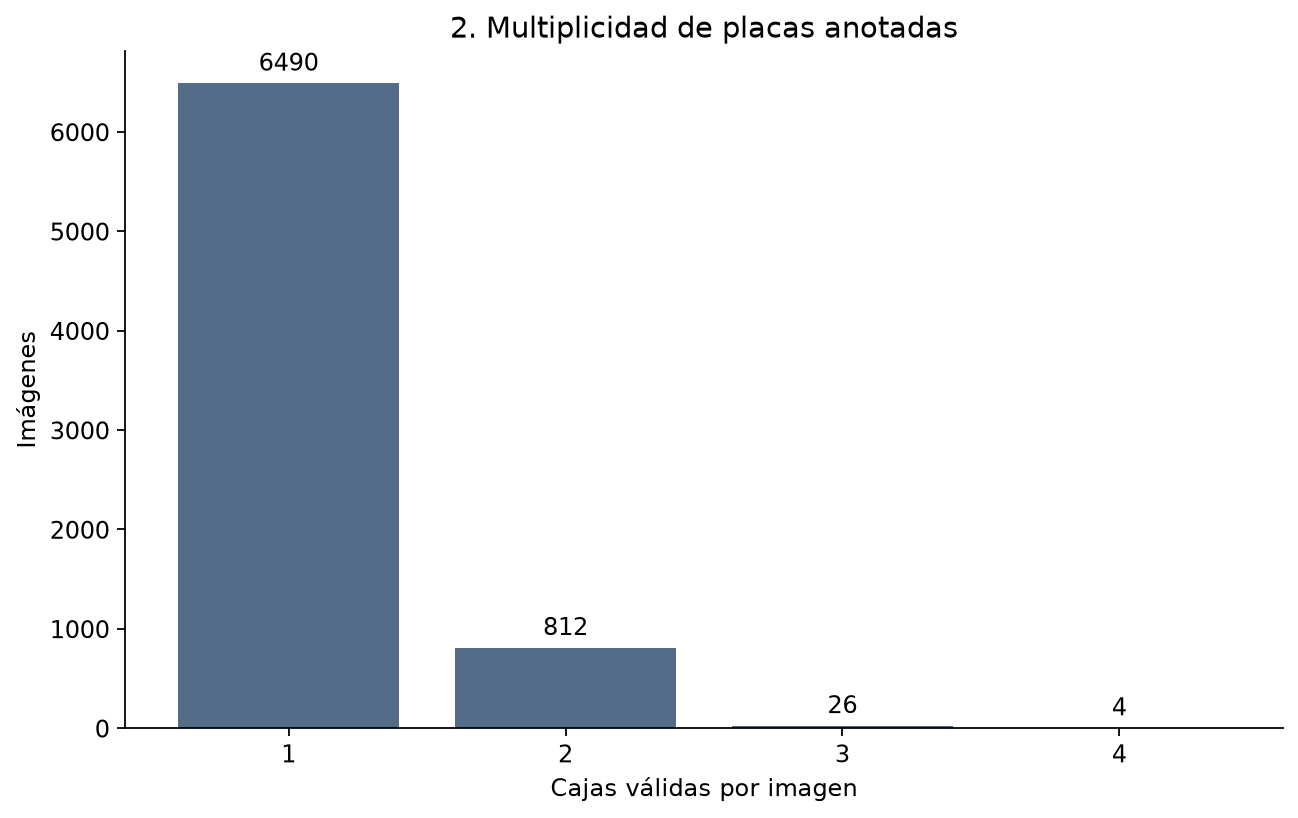

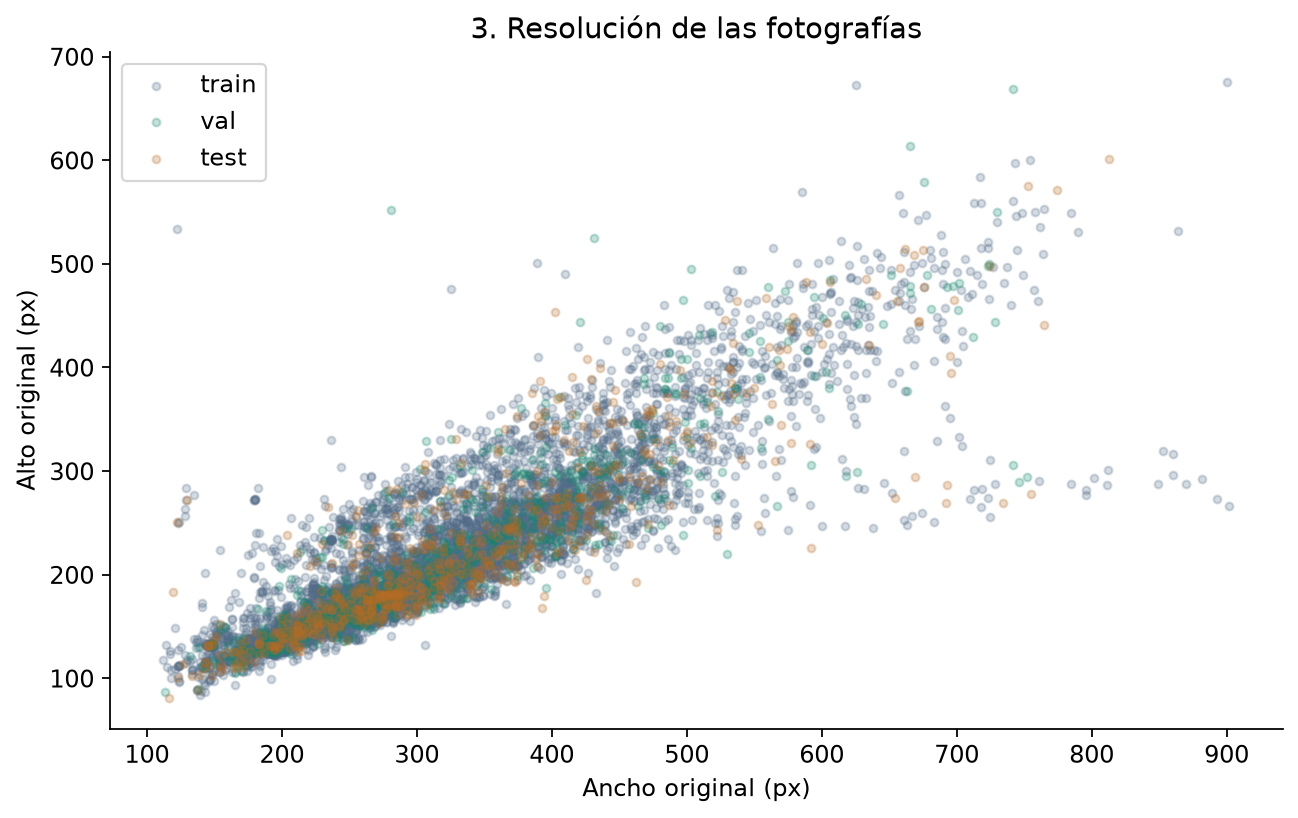

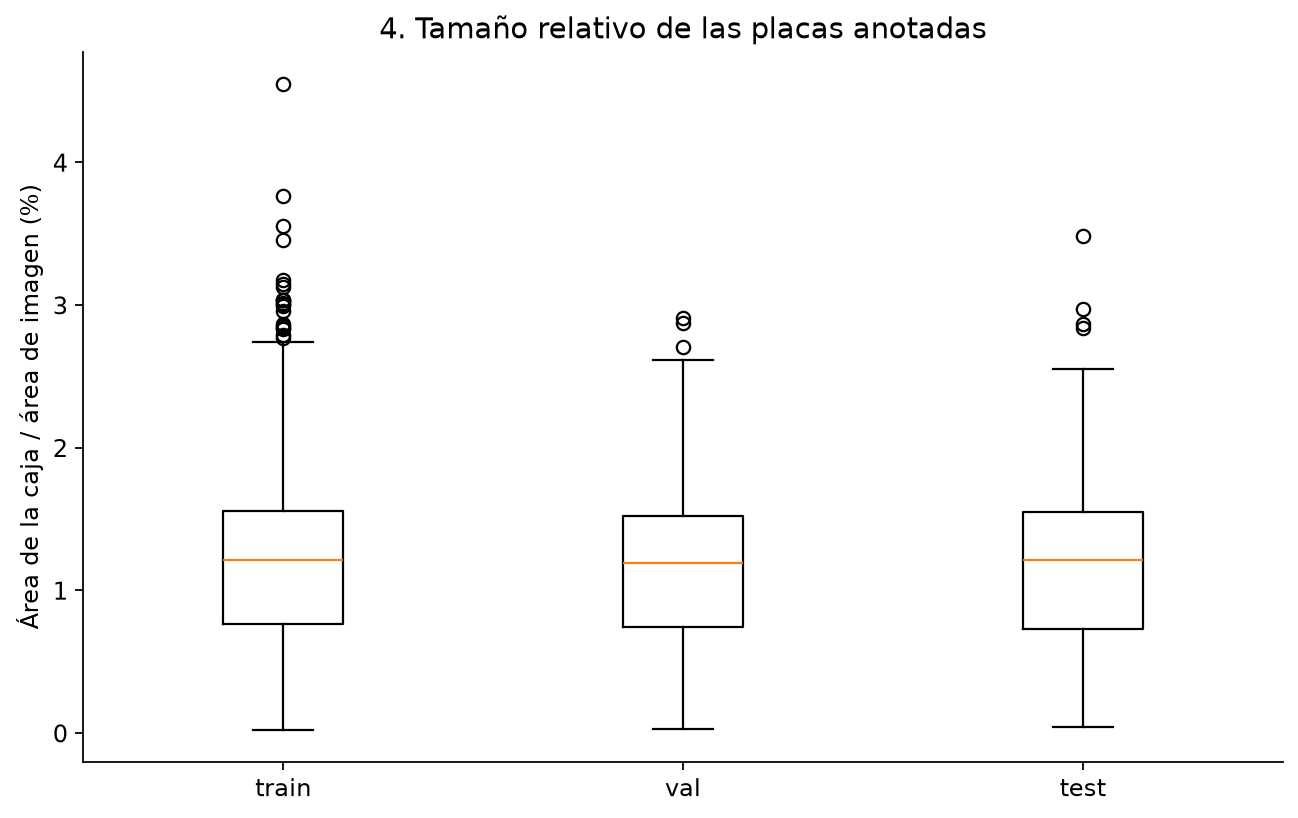

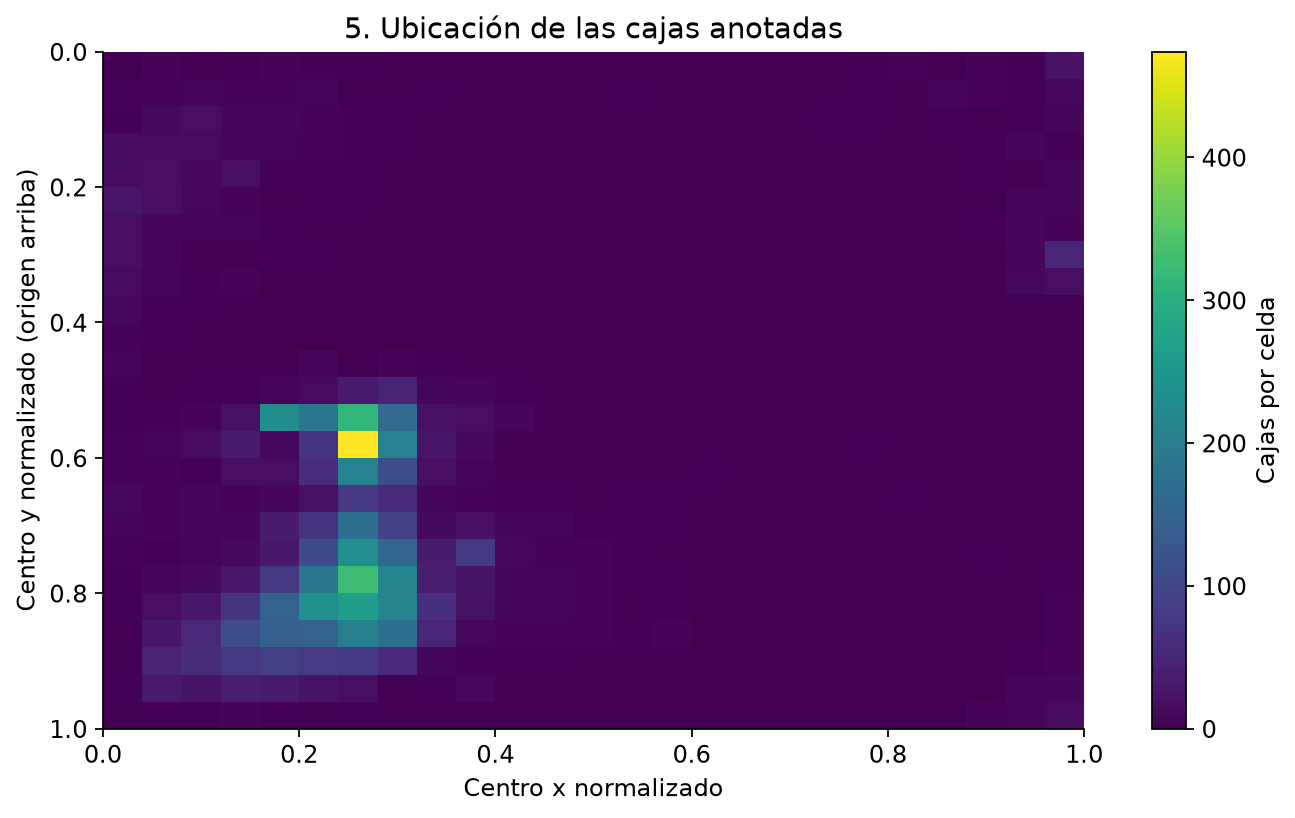

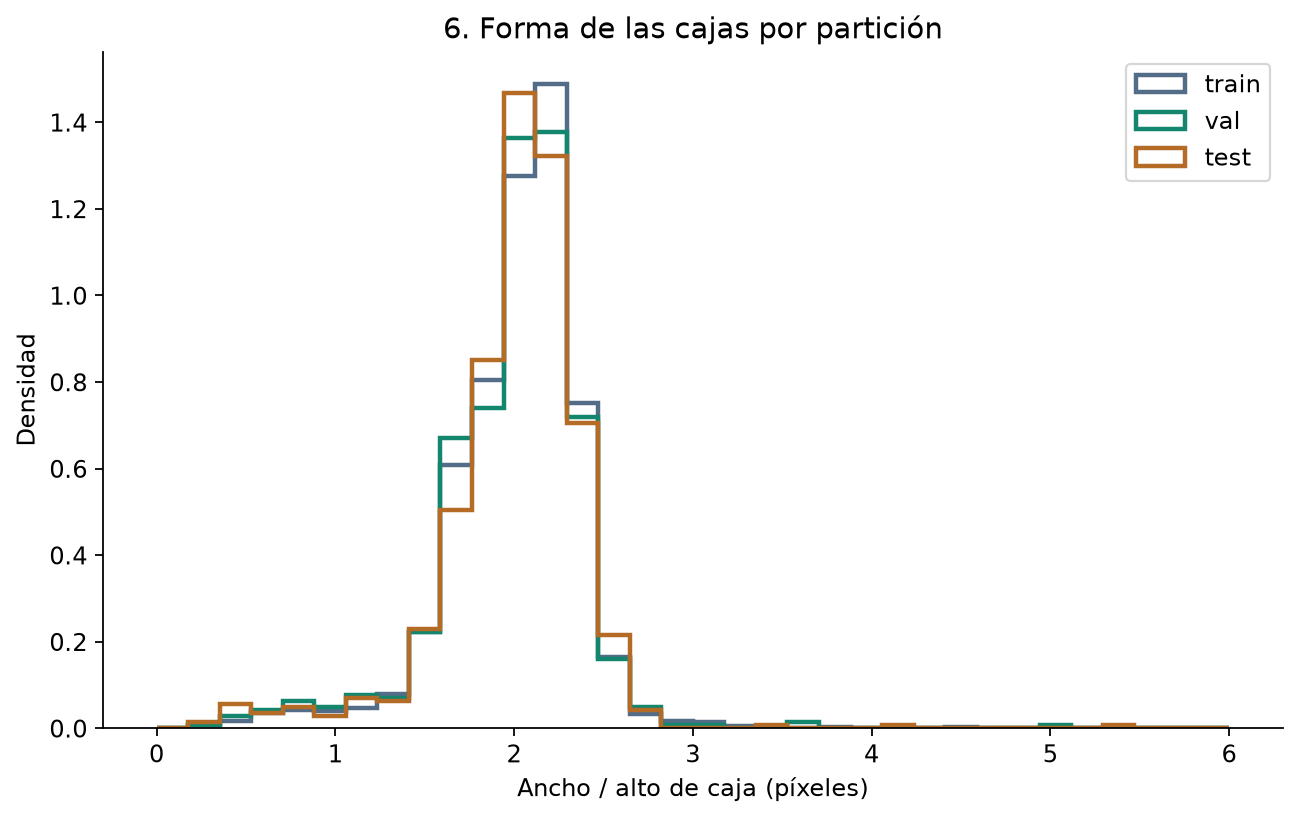

In [3]:
for name in ["01_particiones.png", "02_placas_por_imagen.png", "03_resoluciones.png", "04_area_placas.png", "05_centros.png", "06_forma_placas.png"]:
    display(Image(filename=str(ROOT / "results/figures/eda" / name), width=800))

In [4]:
table([{"variable": k, **eda[k]} for k in ["image_width_px","image_height_px","box_area_pct","box_height_px"]])
print("Cajas de alto <16 px (%):",round(100*eda["box_height_below_16_px"]/eda["total_valid_boxes"],2))
print("Duplicados exactos:", eda["decoded_pixel_duplicates"])

variable,min,q25,median,q75,max,mean,std
image_width_px,112.0,244.0,297.0,389.0,902.0,325.03286961265684,118.42408045329657
image_height_px,81.0,164.0,202.0,265.0,675.0,223.788188761593,82.87704600256737
box_area_pct,0.0234834664,0.7591134053,1.2101836505999999,1.555192616,4.549664266000001,1.1768116418054215,0.5277939093783698
box_height_px,2.9999860000000003,15.000046,18.000061,22.999956,77.999762,19.37256506493665,5.931180376176046


Cajas de alto <16 px (%): 30.82
Duplicados exactos: {'duplicate_groups': 0, 'images_in_duplicate_groups': 0, 'cross_split_groups': 0}


## Interpretación y límites

No existen negativos anotados; falta evaluar falsas detecciones en imágenes sin placa. Las cajas pequeñas pueden dificultar OCR, sin demostrar causalidad. El tamaño de las particiones no garantiza independencia por sesión/vehículo. Para regenerar toda la auditoría local, con el dataset disponible, ejecutar `python -m src.analizar_datos`; no altera las particiones.